# Exploring the Sensitivity of Photosynthesis and Stomatal Resistance Parameters in a Land Surface Model

__Jennifer L. Jefferson__<sup>1,2,a</sup>, __Reed M. Maxwell__<sup>1,2,3</sup> and __Paul G. Constantine__<sup>4</sup>

<sup>1</sup> Hydrologic Science and Engineering Program, Colorado School of Mines, Golden, Colorado<br>
<sup>2</sup> Department of Geology and Geological Engineering, Colorado School of Mines, Golden, Colorado<br>
<sup>3</sup> Integrated Groundwater Modeling Center, Colorado School of Mines, Golden, Colorado<br>
<sup>4</sup> Department of Applied Mathematics and Statistics, Colorado School of Mines, Golden, Colorado<br>
<sup>a</sup> Current affiliation (2017): Wisconsin Department of Natural Resources, Madison, Wisconsin

__Ryan Howard__, Colorado School of Mines (2016 notebook)

<br>

This notebook summarizes the active subspace analysis of transpiration and stomatal resistance in the ParFlow Common Land Model (PF-CLM) in [[1]][R1], with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. The study is also in the first author's PhD thesis [[2]][R2], which the 2016 version of this notebook cited. The notebook runs in Python 3 with numpy and matplotlib (see the repository's `requirements.txt`) in under half a minute. It uses no random numbers.

### Introduction

Vegetation on the land surface takes water from the subsurface and releases it into the atmosphere in a process called _transpiration_, which can be a significant part of the latent heat flux between the ground and the atmosphere. Land surface models condense the plant physiology that controls transpiration into one term, the _stomatal resistance_, for which several parameterizations exist. The Ball–Berry parameterization depends on the rate of photosynthesis, which is limited by carboxylation, by light, or by the export of reaction products. Together, the stomatal resistance and photosynthesis equations need 20 parameters ([[1]][R1] Table 1). We want to know how sensitive the model output is to them.

For the sensitivity analysis we use the _active subspace_ method, which ranks the parameters by importance and gives a low-dimensional view of the relationship between inputs and output. The model is PF-CLM, and the quantities of interest are transpiration, the stomatal resistance of the sunlit part of the canopy, and the stomatal resistance of the shaded part. The forcing is one year of atmospheric data from the Tonzi Ranch in California, September 2002 to August 2003, the average year of the three Tonzi years in [[1]][R1]. We look at monthly and hourly averages to see how the sensitivities change with time.

### Active Subspaces

Consider a model's output, $f$, as a function of normalized input parameters, $\mathbf x$: $f = f(\mathbf x)$. The active subspace method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\rho$ is a probability density on $\mathbf x$ and $\mathbf W\Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$ with the eigenvalues in descending order. The eigenvalues quantify how much $f$ changes, on average, along their eigenvectors; if the first $n$ eigenvalues are much larger than the rest, then $f$ might be well characterized on the span of the first $n$ eigenvectors ([[3]][R3], [[4]][R4]).

Approximating $\mathbf C$ requires the gradient of $f$ with respect to $\mathbf x$. We don't have gradients for PF-CLM, so we use the following algorithm ([[1]][R1] §2c, [[3]][R3] Algorithm 1.3) to identify the _single_ most important direction in the parameter space:

1. Take samples $\{\mathbf x_j\}_{j=1}^M$ of the inputs and compute $f_j = f(\mathbf x_j)$ for every $j$. (Here the samples are not independent draws from one uniform density: two inputs take three discrete values each; see "The data" below.)
2. Fit the linear approximation $f_j\approx a_0 + \hat{\mathbf a}^T\mathbf x_j$ by least squares.
3. The most important direction in the input space is $\mathbf w = \hat{\mathbf a}/\|\hat{\mathbf a}\|$.

Larger-magnitude components of $\mathbf w$ (the _weights_) indicate greater sensitivity to the corresponding parameter. A _sufficient summary plot_ shows the outputs $f_j$ against the active variable $\mathbf w^T\mathbf x_j$; if it shows a tight univariate trend, we can reasonably characterize the output as a function of the active variable.

The direction $\mathbf w$ is a heuristic, and the summary plot is its check. If $f$ is linear, $\mathbf w$ is the first eigenvector of $\mathbf C$, but in general the two differ ([[3]][R3] §1.2). For uniform inputs the least-squares slope recovers a direction of $f$ only under a linearity condition that the hypercube satisfies only in special cases (Li [[5]][R5]), and it can miss the direction entirely when $f$ is not monotonic ([[3]][R3] §1.3). The v1 library says so with a `validity.assumption` warning, which we print below.

The sign of $\mathbf w$ is that of $\hat{\mathbf a}$, as in [[1]][R1] (§2c, Fig. 2): a positive weight means that increasing that input increases the active variable, and the output increases along the active variable. The v1 library returns this sign. The 2016 notebook used the 2016 library's sign rule (first component positive) and flipped October by hand; with that rule every stomatal resistance panel is mirrored relative to Figs. 7 and 9 of [[1]][R1] (compared below).

### The Hydrologic Model

PF-CLM couples the ParFlow integrated hydrologic model to the Common Land Model, a set of algebraic and differential equations for energy and mass fluxes; its solution gives our quantities of interest. The 20 parameters and their ranges, defaults and units, as in Table 1 of [[1]][R1], are below. The table and every plot list them in this order (the data files use another order).

Parameter | Name | Range | Default | Unit
:---------|:-----|:------|:--------|:----
Maximum rate of carboxylation at 25°C | vcmx25 | U(20, 65) | 33 | µmol CO<sub>2</sub> m<sup>−2</sup> s<sup>−1</sup>
Temperature coefficient for vcmx25 | avcmx | U(2.2, 2.6) | 2.4 | –
Deactivation energy constant | hv | U(218000, 242000) | 220000 | J mol<sup>−1</sup>
Entropy constant | sv | U(640, 730) | 710 | J mol<sup>−1</sup> K<sup>−1</sup>
CO<sub>2</sub> Michaelis–Menten constant at 25°C | kc25 | U(25, 50) | 30 | Pa
Temperature coefficient for kc25 | akc | U(1.9, 2.3) | 2.1 | –
O<sub>2</sub> Michaelis–Menten constant at 25°C | ko25 | U(30000, 45000) | 30000 | Pa
Temperature coefficient for ko25 | ako | U(1.1, 1.3) | 1.2 | –
Maximum ratio of oxygenation to carboxylation | ocr | U(0.18, 0.77) | 0.21 | –
In denominator of $w_j$, $c_i$ multiplier | wj1 | {1, 4, 4.5} <sup>b</sup> | 1 | –
In denominator of $w_j$, $c_p$ multiplier | wj2 | {2, 8, 10.5} <sup>b</sup> | 2 | –
Energy content of photons | ecp | U(3.3, 5.8) | 4.6 | µmol J<sup>−1</sup>
Quantum efficiency at 25°C | qe25 | U(0.04, 0.08) | 0.06 | µmol CO<sub>2</sub> µmol photon<sup>−1</sup>
Multiplier in $w_e$ | we1 | U(0.45, 0.55) | 0.50 | –
Partial pressure of CO<sub>2</sub> in the atmosphere | ppcd | U(355, 400) | 355 | ppm <sup>c</sup>
Ratio of diffusivity of CO<sub>2</sub> to H<sub>2</sub>O in the boundary layer | drb | U(1.3, 1.4) | 1.37 | –
Ratio of diffusivity of CO<sub>2</sub> to H<sub>2</sub>O through stomata | drs | U(1.6, 1.7) | 1.65 | –
Minimum leaf conductance (Ball–Berry intercept) | bp | U(1000, 10000) | 2000 | µmol m<sup>−2</sup> s<sup>−1</sup>
Slope of the conductance–photosynthesis relationship (Ball–Berry slope) | mp | U(4, 12) | 9 | –
Maximum stomatal resistance | rsmax0 | U(10000, 40000) | 20000 | s m<sup>−1</sup>

<sup>b</sup> wj1 and wj2 are hard-coded in CLM, and Table 1 of [[1]][R1] gives their ranges as these three values (the 2016 notebook wrote U(1, 4.5) and U(2, 10.5)). In the data each level appears in about 100 runs, and the two inputs are crossed in all 9 combinations (printed below). They are normalized like the other inputs, with bounds [1, 4.5] and [2, 10.5], so their levels sit at −1, 0.714, 1 (wj1) and −1, 0.412, 1 (wj2), and their linear weight summarizes the effect of switching between three formulations.<br>
<sup>c</sup> The data files store ppcd as a mole fraction, mol mol<sup>−1</sup> (3.55e-4 to 4e-4). The normalization is the same in either unit.

### The data

PF-CLM was run for one year of hourly forcing ([[1]][R1] §2b) at each of 300 sets of parameter values (the _realizations_), plus once at the default values. The files hold 301 rows: row 0 is the default run (all 20 values equal the Default column of the table; checked below), and rows 1–300 are the realizations. [[1]][R1] keeps the two apart ("the default simulation and the 300 realizations", p. 909), so **the fits use rows 1–300 only**; the files are unchanged. Including row 0 changes no conclusion (checked below).

The quantities of interest are the transpiration rate (`tran_veg`) and the sunlit and shaded stomatal resistance (`rssun`, `rssha`), averaged two ways:

- **monthly**: means of the daytime hourly values for each month, September 2002 to August 2003 (12 values per run);
- **hourly**: means of the daytime values for each hour of the day over June–August 2003 (14 values per run, hours UTC 12 to UTC 1). The data label the hours in UTC (GMT). Fig. 8 of [[1]][R1] gives local times from 6 am (UTC 12) to 7 pm (UTC 1), i.e. UTC−6. Pacific daylight time, in effect in California in summer, is UTC−7, which would make UTC 12 5 am. Which offset is right is not known, so we label the hours in UTC.

That is 78 quantities in all (26 per output), each with its own linear fit. The files give no units. We infer them from [[1]][R1]: transpiration in mm s<sup>−1</sup> (equivalently kg m<sup>−2</sup> s<sup>−1</sup>; times 86400 it gives 0.04 to 7.2 mm d<sup>−1</sup> for the monthly and 0.03 to 10.4 for the hourly means, on the scales of Figs. 4f and 9d), and stomatal resistance in s m<sup>−1</sup> (Figs. 7 and 9). We plot transpiration in mm d<sup>−1</sup>, as [[1]][R1] does.

[[1]][R1] also ran forcing from Colorado, Oklahoma and the wet and dry Tonzi years (2,100 runs in all); those runs are not in this repository.

### References:

[[1]][R1] J.L. Jefferson, R.M. Maxwell, P.G. Constantine. _Exploring the sensitivity of photosynthesis and stomatal resistance parameters in a land surface model_. J. Hydrometeorol., 18(3):897–915, 2017. doi:10.1175/JHM-D-16-0053.1

[[2]][R2] J.L. Jefferson. _Exploring sensitivities of latent heat parameterizations using a coupled, integrated hydrologic model_. PhD thesis, Colorado School of Mines, 2016. hdl:11124/170080

[[3]][R3] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[4]][R4] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[5]][R5] K.-C. Li. _Sliced inverse regression for dimension reduction_. J. Amer. Statist. Assoc., 86(414):316–327, 1991. doi:10.1080/01621459.1991.10475035

[R1]: https://doi.org/10.1175/JHM-D-16-0053.1
[R2]: https://hdl.handle.net/11124/170080
[R3]: https://doi.org/10.1137/1.9781611973860
[R4]: https://doi.org/10.1137/130916138
[R5]: https://doi.org/10.1080/01621459.1991.10475035

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077. The study in [[1]][R1] was also supported by the National Science Foundation Water Sustainability and Climate Grant WSC-1204787.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()

We read the inputs, the bounds and the six output files. The input file has a header row of parameter names, and the rows of `param_ranges.txt` follow the same order; we reorder both to the order of the table. The hourly files store their columns as UTC 0, 1, 12, …, 23; we reorder them by name to UTC 12, …, 23, 0, 1.

In [2]:
def read_named(fn):
    """Read a space-separated file with one header row of quoted names."""
    with open(fn) as fh:
        names = [h.strip('"') for h in fh.readline().split()]
    return names, np.loadtxt(fn, skiprows=1, ndmin=2)


# Table 1 of [1]: name, default, unit (in this order)
TABLE = [('vcmx25', 33, 'umol CO2 m-2 s-1'), ('avcmx', 2.4, None), ('hv', 220000, 'J mol-1'),
         ('sv', 710, 'J mol-1 K-1'), ('kc25', 30, 'Pa'), ('akc', 2.1, None), ('ko25', 30000, 'Pa'),
         ('ako', 1.2, None), ('ocr', .21, None), ('wj1', 1, None), ('wj2', 2, None), ('ecp', 4.6, 'umol J-1'),
         ('qe25', .06, 'umol CO2 umol photon-1'), ('we1', .5, None), ('ppcd', 355e-6, 'mol mol-1'),
         ('drb', 1.37, None), ('drs', 1.65, None), ('bp', 2000, 'umol m-2 s-1'), ('mp', 9, None),
         ('rsmax0', 20000, 's m-1')]
names = [t[0] for t in TABLE]
m = len(names)

file_names, X_all = read_named('stomata_realization_inputs.txt')
order = [file_names.index(n) for n in names]
X_all = X_all[:, order]                                  # columns in table order
_, bounds = read_named('param_ranges.txt')               # rows in file order
lb, ub = bounds[order].T

MONTHS = ['September', 'October', 'November', 'December', 'January', 'February',
          'March', 'April', 'May', 'June', 'July', 'August']
HOURS = [f'GMT_{h}' for h in (12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 0, 1)]
SCALES = {'monthly': ('mo_avg', MONTHS), 'hourly': ('JJA_hr_avg', HOURS)}
QOIS = ['tran_veg', 'rssun', 'rssha']
slice_labels = {'monthly': [s[:3] for s in MONTHS], 'hourly': [f'UTC {s[4:]}' for s in HOURS]}

F_all = {}
for scale, (prefix, cols) in SCALES.items():
    for q in QOIS:
        header, data = read_named(f'Tonzi_Stomata_SC.{prefix}_{q}.txt')
        F_all[scale, q] = data[:, [header.index(c) for c in cols]]

print(f'inputs {X_all.shape}, bounds {bounds.shape}; outputs: ' +
      ', '.join(f'{s} {q} {F.shape}' for (s, q), F in F_all.items()))
print(f'all outputs positive and finite: {all(np.all(np.isfinite(F) & (F > 0)) for F in F_all.values())}')
default = np.array([t[1] for t in TABLE], dtype=float)
print(f'row 0 equals the Table 1 defaults: {np.allclose(X_all[0], default, rtol=1e-12, atol=0)}')
for n in ('wj1', 'wj2'):
    lev, cnt = np.unique(X_all[1:, names.index(n)], return_counts=True)
    print(f'{n}, rows 1-300: levels {lev.tolist()}, runs per level {cnt.tolist()}')
_, cnt = np.unique(X_all[1:, [names.index('wj1'), names.index('wj2')]], axis=0, return_counts=True)
print(f'(wj1, wj2) combinations: {len(cnt)}, runs per combination {cnt.min()} to {cnt.max()}')
print(f'ppcd bounds as stored: {lb[names.index("ppcd")]:g} to {ub[names.index("ppcd")]:g} (mol mol-1)')
for (s, q), Fk in F_all.items():
    lo, hi = Fk[1:].min(), Fk[1:].max()
    extra = f' (x 86400: {86400 * lo:.2f} to {86400 * hi:.1f} mm d-1)' if q == 'tran_veg' else ' (s m-1)'
    print(f'{s:>8} {q:>8}, rows 1-300: {lo:.3g} to {hi:.3g}{extra}')

inputs (301, 20), bounds (20, 2); outputs: monthly tran_veg (301, 12), monthly rssun (301, 12), monthly rssha (301, 12), hourly tran_veg (301, 14), hourly rssun (301, 14), hourly rssha (301, 14)
all outputs positive and finite: True
row 0 equals the Table 1 defaults: True
wj1, rows 1-300: levels [1.0, 4.0, 4.5], runs per level [93, 98, 109]
wj2, rows 1-300: levels [2.0, 8.0, 10.5], runs per level [87, 104, 109]
(wj1, wj2) combinations: 9, runs per combination 28 to 41
ppcd bounds as stored: 0.000355 to 0.0004 (mol mol-1)
 monthly tran_veg, rows 1-300: 5.13e-07 to 8.38e-05 (x 86400: 0.04 to 7.2 mm d-1)
 monthly    rssun, rows 1-300: 241 to 7.89e+03 (s m-1)
 monthly    rssha, rows 1-300: 1.01e+03 to 2.32e+04 (s m-1)
  hourly tran_veg, rows 1-300: 3.57e-07 to 0.00012 (x 86400: 0.03 to 10.4 mm d-1)
  hourly    rssun, rows 1-300: 380 to 9.69e+03 (s m-1)
  hourly    rssha, rows 1-300: 1.2e+03 to 3.2e+04 (s m-1)


The input space is uniform on the box of the table (`ac.Uniform`), which v1 maps to $[-1, 1]^{20}$. Every sample lies inside the box. We keep rows 1–300 for the analysis and row 0 aside.

In [3]:
space = ac.Uniform(lower=lb, upper=ub, names=names, units=[t[2] for t in TABLE])
print(f'all 301 rows inside the box: {space.contains(X_all).all()}')

X = X_all[1:]                                             # the 300 realizations; row 0 is the default run
F = {key: val[1:] for key, val in F_all.items()}
XX = space.to_normalized(X)
for n in ('wj1', 'wj2'):
    print(f'{n}: normalized levels {np.unique(XX[:, names.index(n)]).round(3).tolist()}')

all 301 rows inside the box: True
wj1: normalized levels [-1.0, 0.714, 1.0]
wj2: normalized levels [-1.0, 0.412, 1.0]


Now we compute the 78 one-dimensional subspaces, one for each output and time slice, with the least-squares estimator above (`estimator="ols"`), each once. (The 2016 notebook computed each of them three times, 234 fits.) Each fit warns `validity.assumption` for the reason given above; we record the warnings and print one.

In [4]:
def recorded(fn, **kw):
    """Call fn(**kw), recording warnings; return the result and the caught warnings."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        result = fn(**kw)
    return result, caught


W = {}                       # W[scale, q]: (number of slices, 20), row i = w for slice i
caught_all = []
for (scale, q), Fk in F.items():
    rows = []
    for i in range(Fk.shape[1]):
        sub, caught = recorded(ac.active_subspace, X=X, f=Fk[:, i], space=space, estimator='ols', n=1)
        rows.append(sub.W1[:, 0])
        caught_all += caught
    W[scale, q] = np.array(rows)
codes = [getattr(w.message, 'code', w.category.__name__) for w in caught_all]
n_fits = sum(len(v) for v in W.values())
print(f'{n_fits} fits; warnings: {sorted(set(codes))}, {len(codes)} in all')
print(f'message: {caught_all[0].message}')

78 fits; warnings: ['validity.assumption'], 78 in all
message: outside the method's assumptions; estimator 'ols' on a uniform space: needs the linearity condition, which the cube satisfies only in special cases [Li1991] [validity.assumption]


**Check against the 2016 notebook.** The 2016 notebook normalized the inputs by hand, used all 301 rows, made the first component of $\mathbf w$ (qe25 in the file order) positive, and flipped monthly sunlit resistance in October by hand. It printed no numbers, so we repeat its computation with numpy and compare directions. First with all 301 rows, as in 2016 (v1 refit on all rows for this check only), then with the 300 realizations used here. The last column gives the sign of $\mathbf w \cdot \mathbf w_{2016}$ per slice.

In [5]:
XX_all = 2 * (X_all - lb) / (ub - lb) - 1                             # the 2016 hand normalization
A_all = np.hstack([np.ones((len(XX_all), 1)), XX_all])
j_first = names.index(file_names[0])                                  # first column of the 2016 data: qe25
W_2016, W_v1_all = {}, {}
for (scale, q), Fk in F_all.items():
    rows, rows_v1 = [], []
    for i in range(Fk.shape[1]):
        a = np.linalg.lstsq(A_all, Fk[:, i], rcond=None)[0][1:]
        w16 = a / np.linalg.norm(a) * np.sign(a[j_first])
        if scale == 'monthly' and q == 'rssun' and MONTHS[i] == 'October':
            w16 = -w16                                                # the 2016 hand flip
        rows.append(w16)
        sub, _ = recorded(ac.active_subspace, X=X_all, f=Fk[:, i], space=space, estimator='ols', n=1)
        rows_v1.append(sub.W1[:, 0])
    W_2016[scale, q], W_v1_all[scale, q] = np.array(rows), np.array(rows_v1)

print(f'{"":>16}{"all 301 rows:":>16}{"300 rows:":>12}')
print(f'{"":>16}{"max ||cos|-1|":>16}{"min |cos|":>12}   sign of w . w_2016 per slice')
for key in W:
    c_all = np.abs(np.sum(W_v1_all[key] * W_2016[key], axis=1))
    c_300 = np.sum(W[key] * W_2016[key], axis=1)
    print(f'{key[0] + " " + key[1]:>16}{np.max(np.abs(c_all - 1)):16.1e}{np.min(np.abs(c_300)):12.4f}   '
          + ''.join('+' if c > 0 else '-' for c in c_300))

                   all 301 rows:   300 rows:
                   max ||cos|-1|   min |cos|   sign of w . w_2016 per slice
monthly tran_veg         3.3e-16      0.9999   ++++++++++++
   monthly rssun         2.2e-16      0.9998   ------------
   monthly rssha         2.2e-16      0.9999   ------------
 hourly tran_veg         4.4e-16      0.9999   ++++++++++++++
    hourly rssun         3.3e-16      0.9997   --------------
    hourly rssha         4.4e-16      0.9999   --------------


The v1 directions on all 301 rows equal the 2016 ones up to sign, to rounding error, and dropping the default run changes each direction by little (smallest $|\cos|$ printed above). The signs agree for transpiration and are opposite in every slice for both resistances: the 2016 resistance figures are mirrored relative to this notebook and to [[1]](https://doi.org/10.1175/JHM-D-16-0053.1). The October hand flip made October agree with the other months in the 2016 convention; with $\mathbf w = \hat{\mathbf a}/\|\hat{\mathbf a}\|$ no slice needs a special case.

**How well does one direction describe each output?** For each slice we fit a straight line to $f$ against the active variable $\mathbf w^T\mathbf x$ and print its $R^2$. Because $\mathbf w$ is the direction of the least-squares fit, this is also the $R^2$ of the 20-input linear model. ([[1]](https://doi.org/10.1175/JHM-D-16-0053.1) reports no $R^2$.)

In [6]:
R2 = {}
for key, Fk in F.items():
    y = XX @ W[key].T                                                 # active variable, one column per slice
    R2[key] = np.array([np.corrcoef(y[:, i], Fk[:, i])[0, 1]**2 for i in range(Fk.shape[1])])

for scale in SCALES:
    print(f'{scale:>8}' + ''.join(f'{q:>10}' for q in QOIS))
    for i, lab in enumerate(slice_labels[scale]):
        print(f'{lab:>8}' + ''.join(f'{R2[scale, q][i]:10.2f}' for q in QOIS))
    print()
for q in QOIS:
    r = np.concatenate([R2[s, q] for s in SCALES])
    print(f'{q:>8}: linear R^2 from {r.min():.2f} to {r.max():.2f}')

 monthly  tran_veg     rssun     rssha
     Sep      0.92      0.78      0.77
     Oct      0.94      0.90      0.77
     Nov      0.95      0.89      0.79
     Dec      0.94      0.86      0.79
     Jan      0.93      0.85      0.82
     Feb      0.94      0.88      0.81
     Mar      0.93      0.81      0.81
     Apr      0.93      0.81      0.81
     May      0.91      0.82      0.80
     Jun      0.92      0.70      0.78
     Jul      0.92      0.46      0.76
     Aug      0.95      0.58      0.77

  hourly  tran_veg     rssun     rssha
  UTC 12      0.99      0.75      0.76
  UTC 13      0.97      0.72      0.76
  UTC 14      0.95      0.71      0.77
  UTC 15      0.95      0.73      0.79
  UTC 16      0.95      0.78      0.79
  UTC 17      0.95      0.77      0.78
  UTC 18      0.94      0.67      0.78
  UTC 19      0.92      0.53      0.77
  UTC 20      0.90      0.44      0.77
  UTC 21      0.89      0.39      0.76
  UTC 22      0.90      0.37      0.75
  UTC 23      0.91      

Transpiration follows its active variable closely in every slice. Shaded resistance has $R^2$ from 0.75 to 0.82, and sunlit resistance varies most: from 0.90 in October down to 0.46 in July, and to 0.37–0.44 in the hours UTC 20–23 of June–August (afternoon in local time). So one direction describes transpiration well, shaded resistance reasonably, and sunlit resistance only partly in summer; the summary plots below show the spread.

### Plots

For each of the six cases (monthly or hourly; transpiration, sunlit or shaded resistance), one figure shows

- **top:** the weights $\mathbf w$ for every slice (one colour per slice). The gray band marks $|w_i| \le 0.25$, the threshold [[1]](https://doi.org/10.1175/JHM-D-16-0053.1) uses for an important parameter (Table 3);
- **middle:** each weight against time. The parameters with $|w_i| > 0.25$ in some slice of any case have a fixed colour in every figure; the others are thin gray lines;
- **bottom:** sufficient summary plots, $f$ against $\mathbf w^T\mathbf x$, several slices per panel, with the $R^2$ from the table above in the legend. Transpiration is in mm d<sup>−1</sup> and resistance in s m<sup>−1</sup> (units inferred), on linear axes as in [[1]](https://doi.org/10.1175/JHM-D-16-0053.1).

Compare with Figs. 4c,f and 7 (monthly) and Fig. 9 (hourly) of [[1]](https://doi.org/10.1175/JHM-D-16-0053.1). The paper orders the parameters as we do.

In [7]:
qoi_title = {'tran_veg': 'Transpiration', 'rssun': 'Sunlit Stomatal Resistance',
             'rssha': 'Shaded Stomatal Resistance'}
qoi_unit = {'tran_veg': 'mm d$^{-1}$', 'rssun': 's m$^{-1}$', 'rssha': 's m$^{-1}$'}
scale_factor = {'tran_veg': 86400., 'rssun': 1., 'rssha': 1.}          # mm s-1 -> mm d-1 for transpiration
groups = {'monthly': [('Sep–Nov', [0, 1, 2]), ('Dec–Feb', [3, 4, 5]), ('Mar–May', [6, 7, 8]),
                      ('Jun–Aug', [9, 10, 11])],
          'hourly': [('Morning, UTC 12–15', [0, 1, 2, 3]), ('Midday, UTC 16–21', [4, 5, 6, 7, 8, 9]),
                     ('Evening, UTC 22–1', [10, 11, 12, 13])]}
important = [n for j, n in enumerate(names) if max(np.abs(Wk[:, j]).max() for Wk in W.values()) > .25]
input_color = {n: plt.cm.tab10(k) for k, n in enumerate(important)}


def plot_case(scale, q):
    """Weights per slice, weights against time, and summary plots for one output and time scale."""
    Wk, Fk, labs = W[scale, q], F[scale, q] * scale_factor[q], slice_labels[scale]
    ns = len(labs)
    colors = plt.cm.viridis(np.linspace(0, .92, ns))
    fig = plt.figure(figsize=(14, 16), layout='constrained')
    top, mid, bot = fig.subfigures(3, 1, height_ratios=[1, 1, 1.05])
    fig.suptitle(f'{scale.capitalize()} {qoi_title[q]}', fontsize=20)

    ax = top.subplots()
    for i in range(ns):
        ax.plot(np.arange(1, m + 1) + .5 * (i / (ns - 1) - .5), Wk[i], 'o', color=colors[i], ms=6, label=labs[i])
    ax.axhspan(-.25, .25, color='0.9', zorder=0)
    ax.axhline(0, color='k', ls='--', lw=.8)
    ax.set_xticks(range(1, m + 1), names, rotation='vertical', fontsize=13)
    ax.set_xlim(0, m + 1); ax.set_ylim(-1, 1); ax.grid(True, alpha=.4)
    ax.set_ylabel('Active variable weight', fontsize=14)
    ax.legend(loc='center left', bbox_to_anchor=(1.01, .5), ncol=1 if ns < 13 else 2, fontsize=10)

    ax = mid.subplots()
    t = np.arange(ns)
    for j, n in enumerate(names):
        if n in important:
            ax.plot(t, Wk[:, j], '-o', color=input_color[n], lw=2, ms=4, label=n)
        else:
            ax.plot(t, Wk[:, j], '-', color='0.6', lw=.8)
    ax.plot([], [], '-', color='0.6', lw=.8, label='other inputs')
    ax.axhspan(-.25, .25, color='0.9', zorder=0)
    ax.axhline(0, color='k', ls='--', lw=.8)
    ax.set_xticks(t, labs, rotation='vertical' if scale == 'hourly' else 0, fontsize=12)
    ax.set_xlim(-.3, ns - .7); ax.set_ylim(-1, 1); ax.grid(True, alpha=.4)
    ax.set_ylabel('Active variable weight', fontsize=14)
    ax.legend(loc='center left', bbox_to_anchor=(1.01, .5), fontsize=10)

    axes = bot.subplots(1, len(groups[scale]), sharey=True)
    y = XX @ Wk.T
    for ax, (title, idx) in zip(axes, groups[scale]):
        for i in idx:
            ax.plot(y[:, i], Fk[:, i], 'o', color=colors[i], ms=4, alpha=.8,
                    label=f'{labs[i]}, $R^2$ = {R2[scale, q][i]:.2f}')
        ax.set_title(title, fontsize=13)
        ax.set_xlabel('Active variable', fontsize=13)
        ax.grid(True, alpha=.4)
        ax.legend(loc='upper left', fontsize=9, markerscale=1.5)
    axes[0].set_ylabel(f'{qoi_title[q]} ({qoi_unit[q]})', fontsize=13)
    plt.show()


print(f'inputs with |w| > 0.25 in some slice of some case: {important}')

inputs with |w| > 0.25 in some slice of some case: ['vcmx25', 'kc25', 'ocr', 'wj1', 'qe25', 'bp', 'mp']


#### Monthly averages

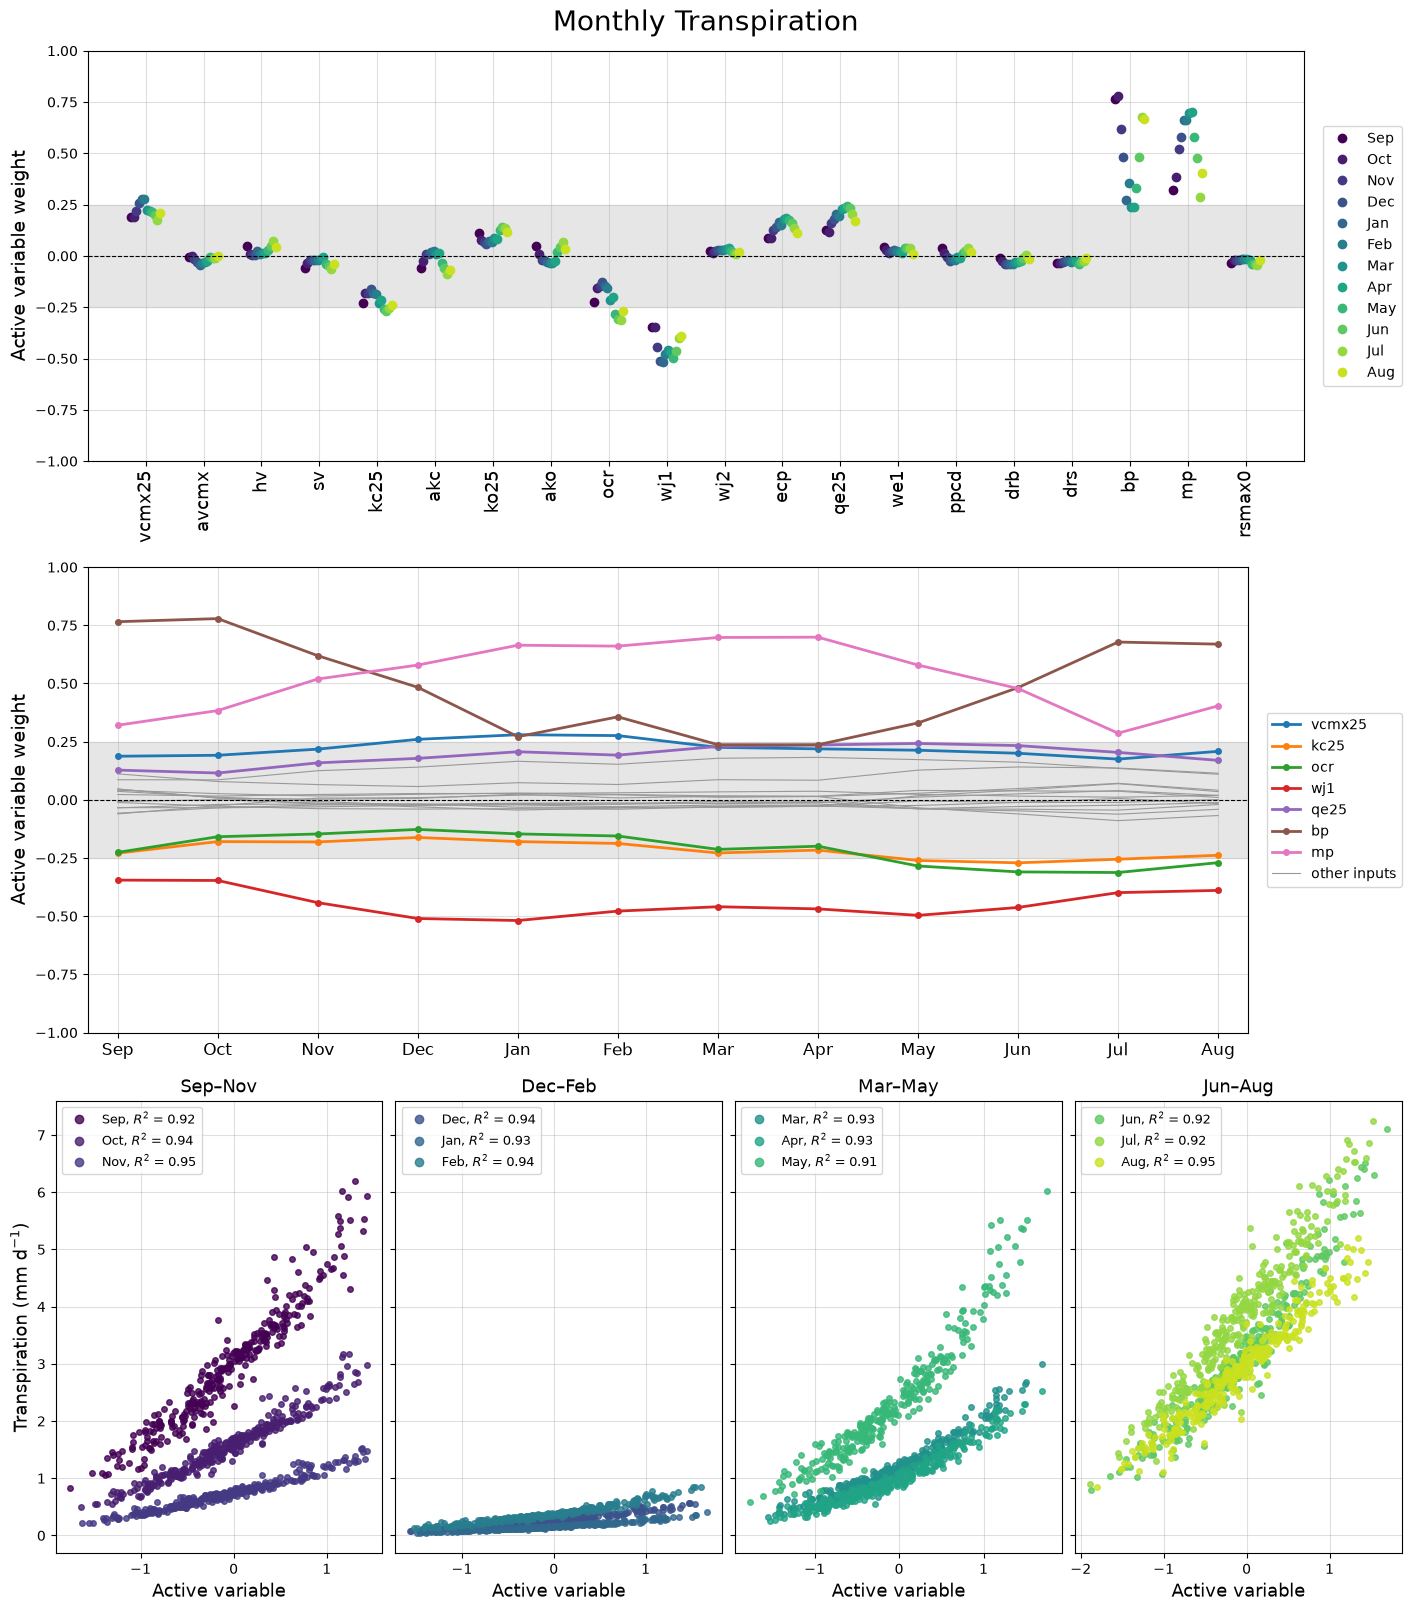

In [8]:
plot_case('monthly', 'tran_veg')

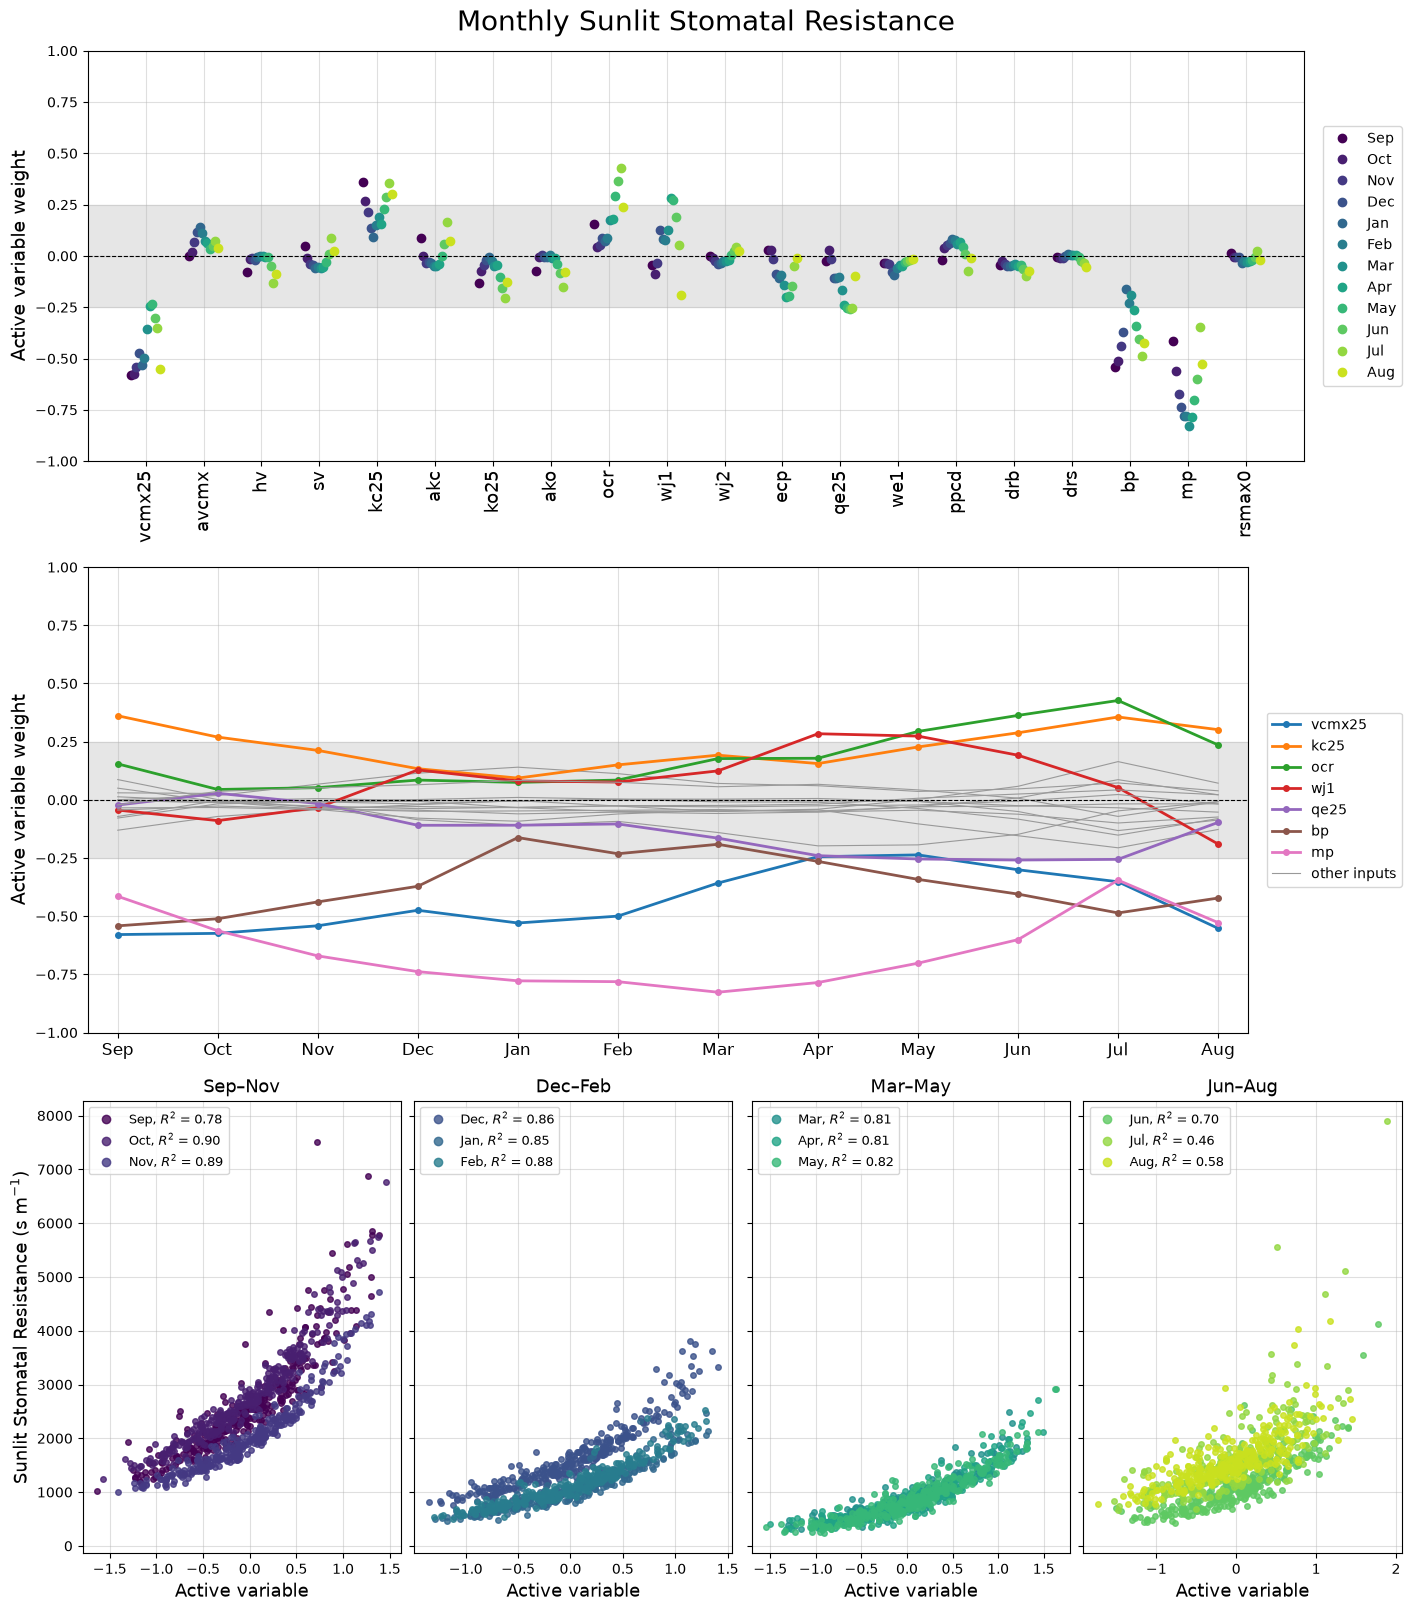

In [9]:
plot_case('monthly', 'rssun')

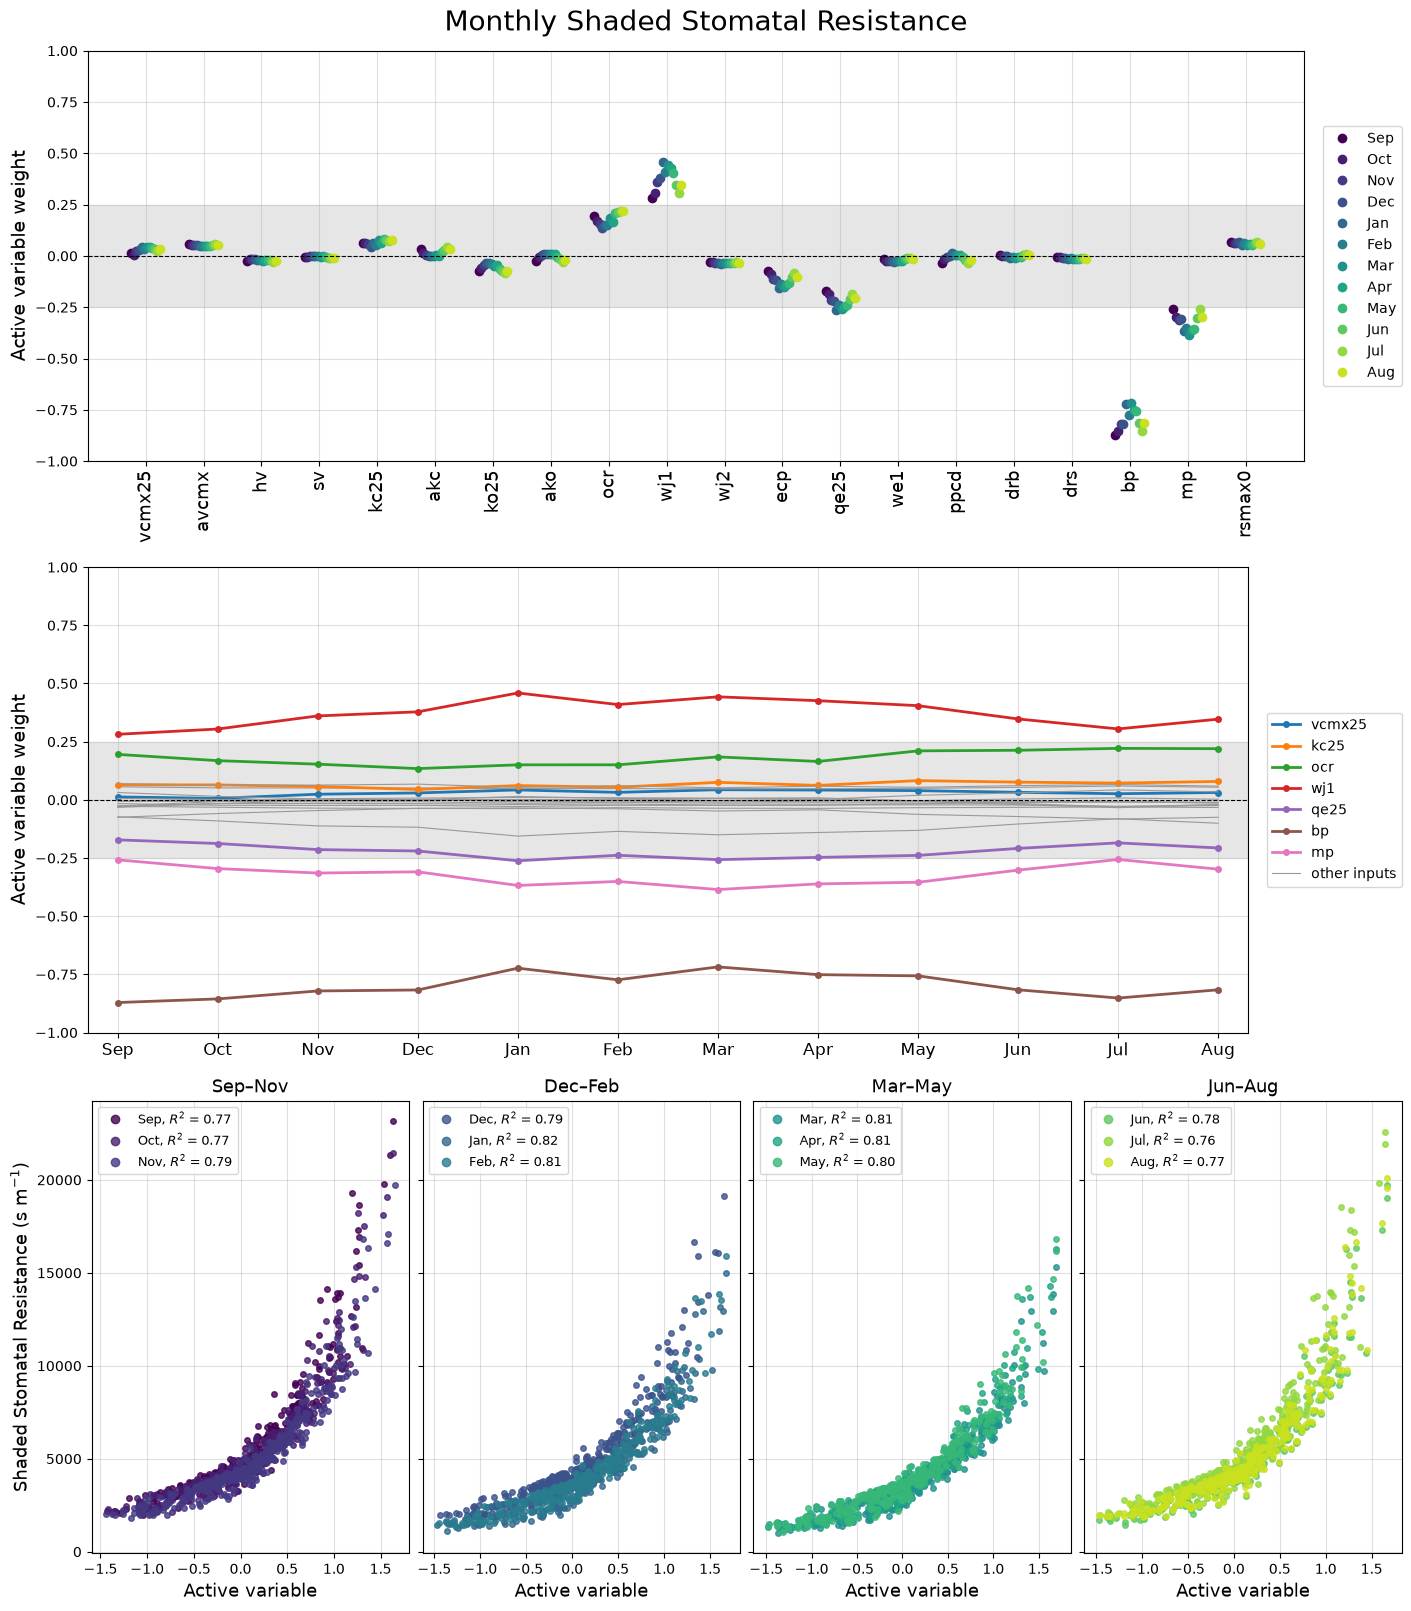

In [10]:
plot_case('monthly', 'rssha')

#### Hourly averages, June–August 2003

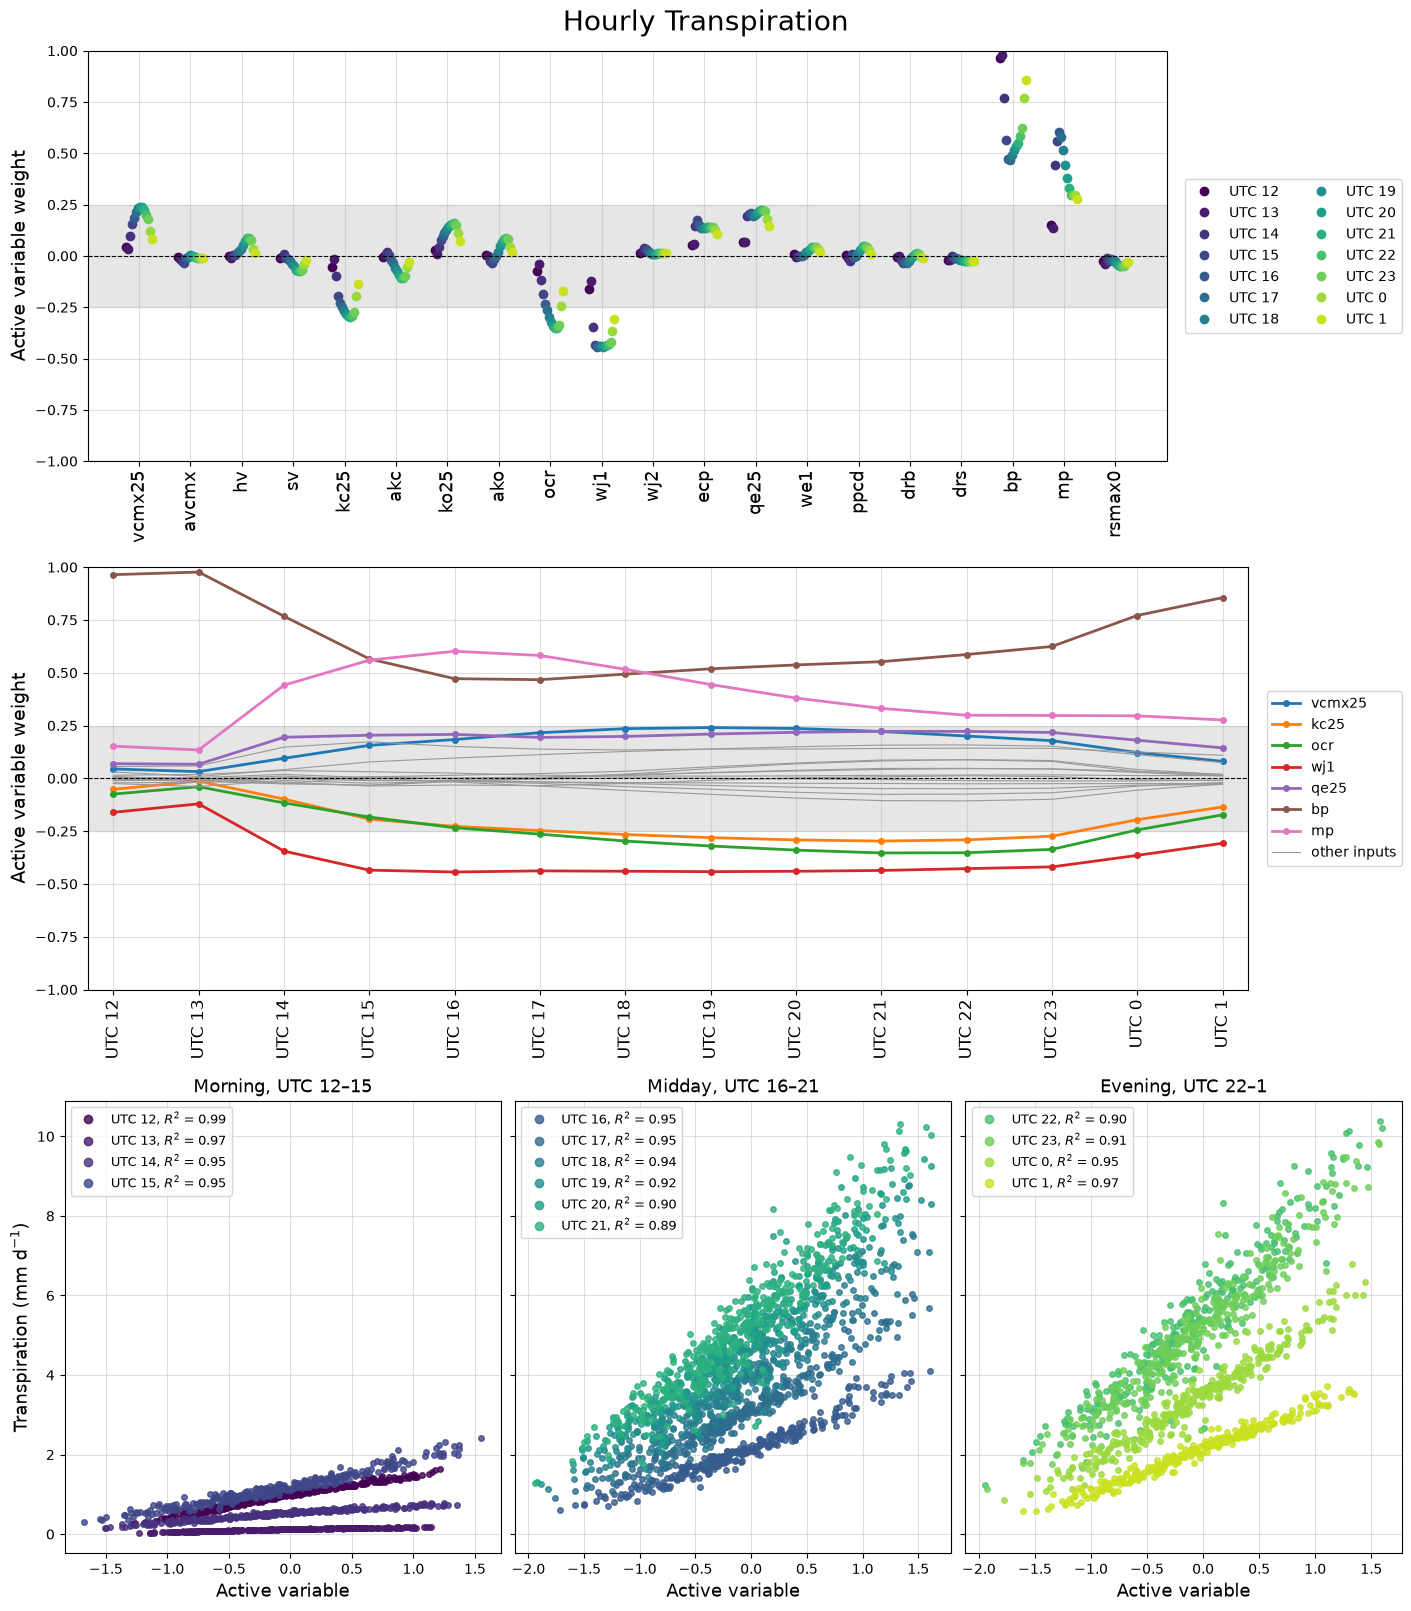

In [11]:
plot_case('hourly', 'tran_veg')

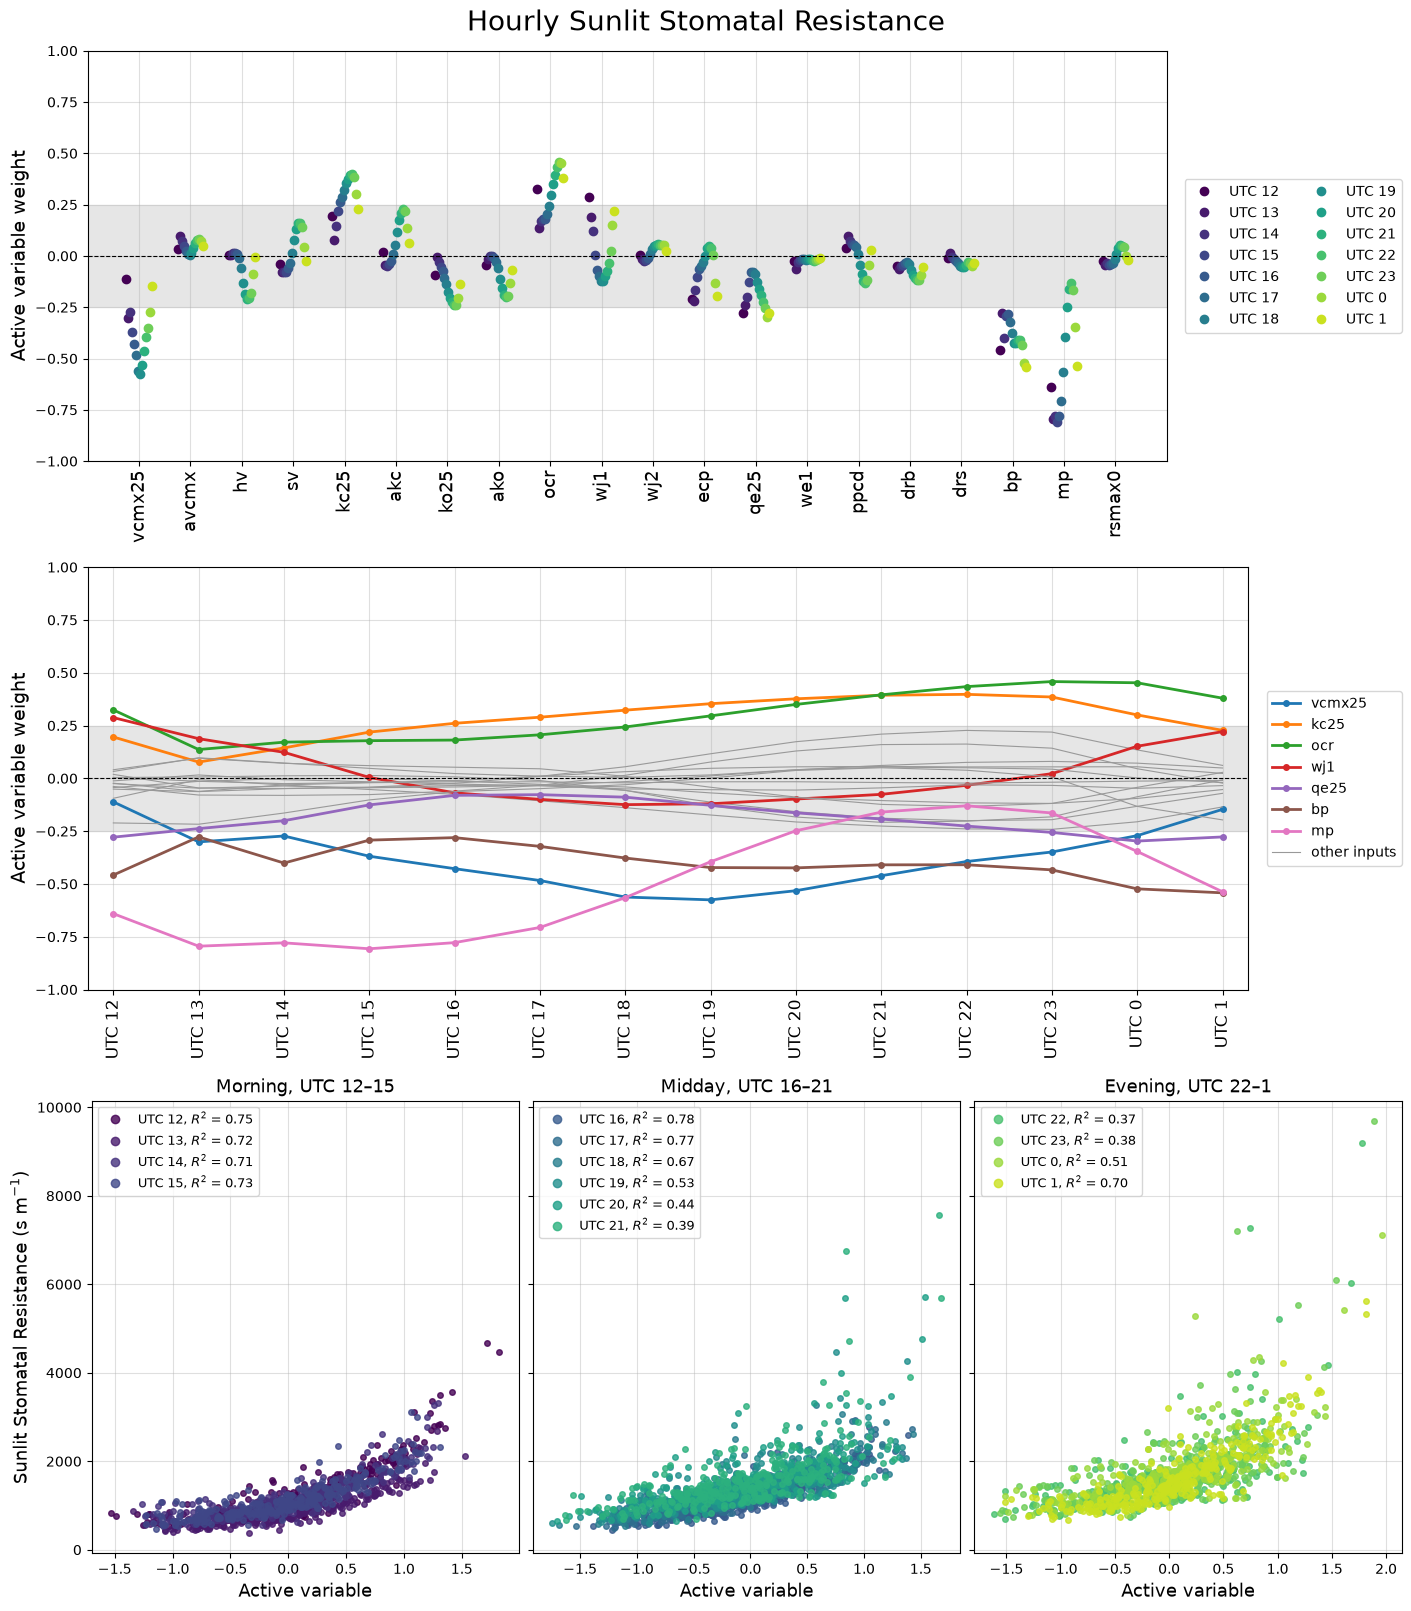

In [12]:
plot_case('hourly', 'rssun')

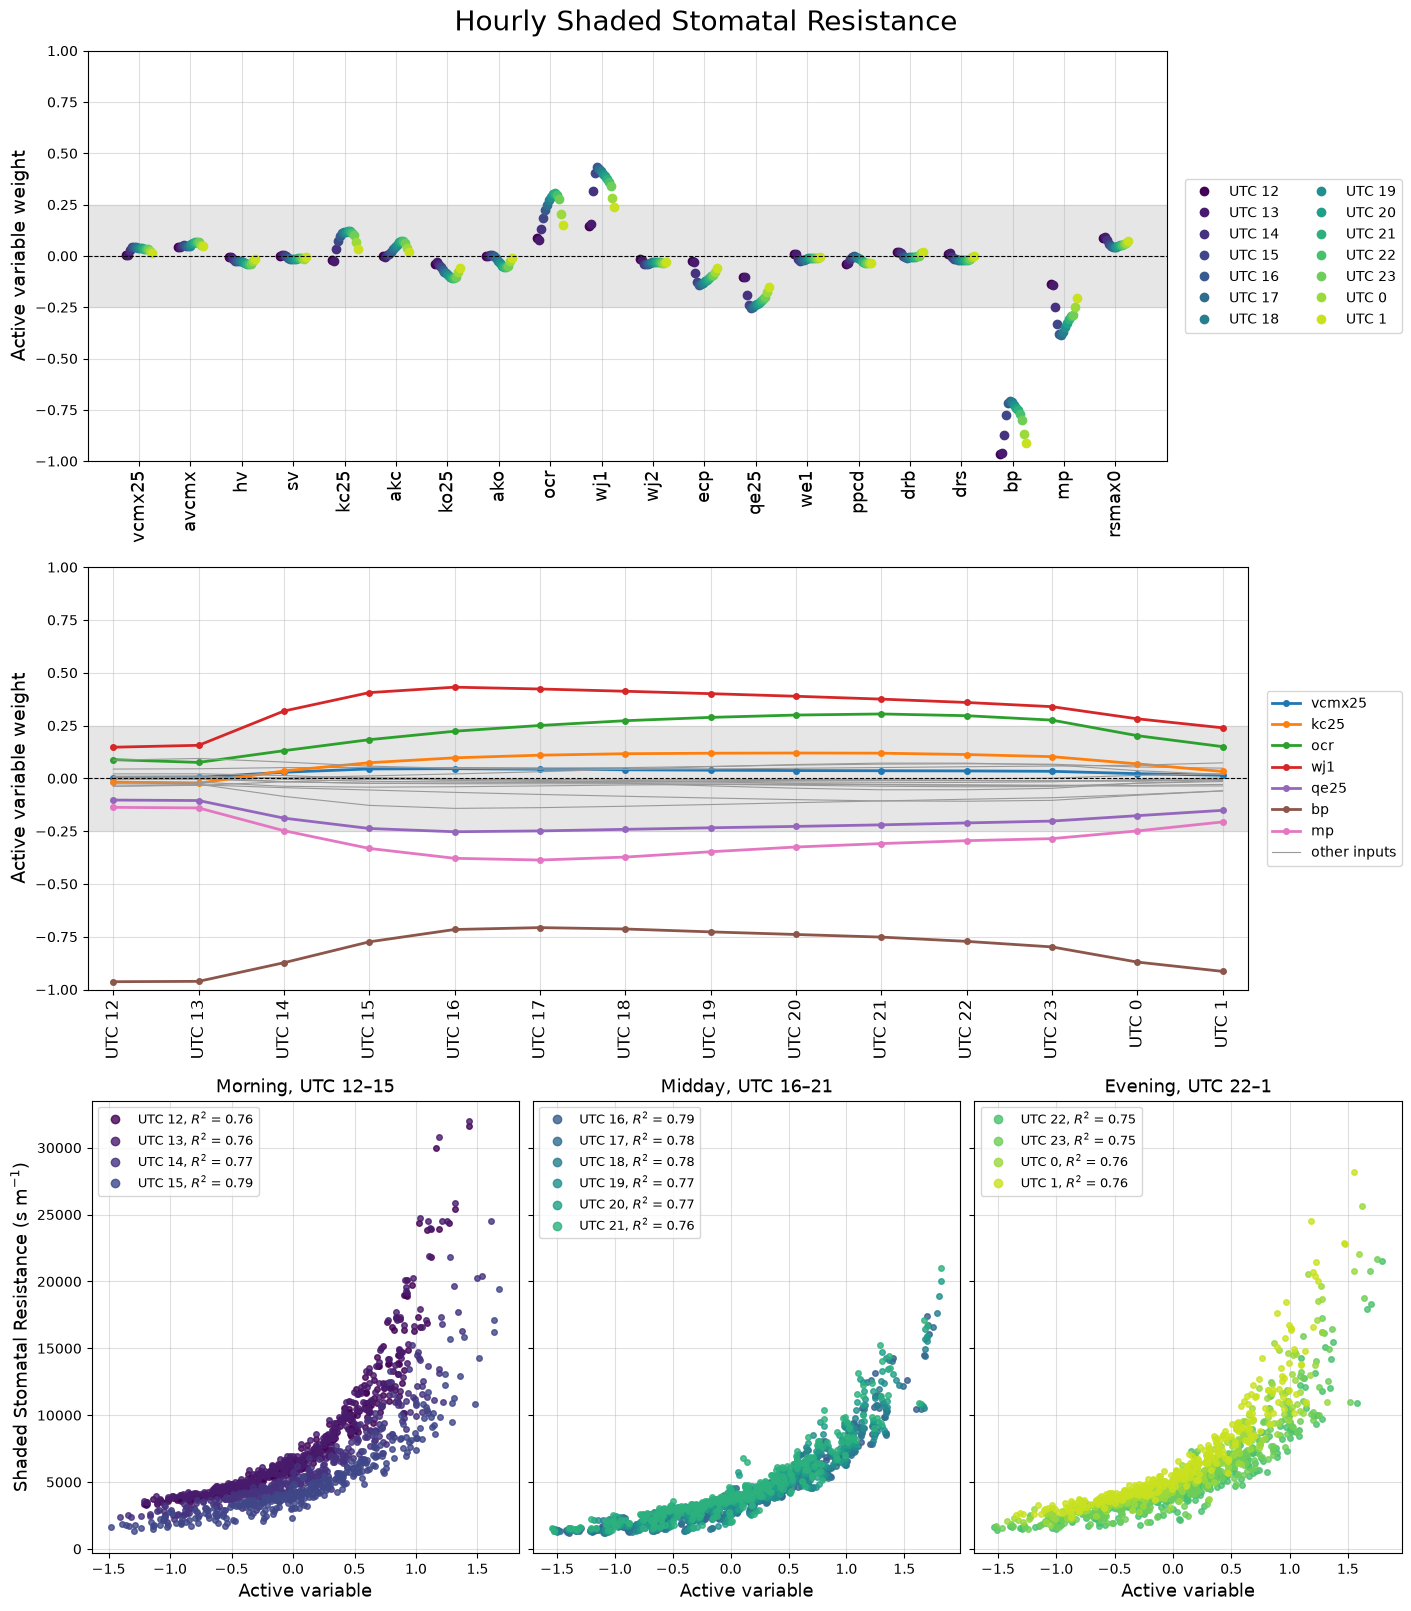

In [13]:
plot_case('hourly', 'rssha')

### Comparison with [[1]](https://doi.org/10.1175/JHM-D-16-0053.1)

We print the range of the bp, mp and wj1 weights over the slices of each case, the largest $|w_{\mathrm{ppcd}}|$, and the smallest cosine between the directions of consecutive slices (positive means that no slice is flipped relative to its neighbours). Then the five parameters with the largest mean $|w_i|$ over the slices of each case, and the parameters with $|w_i| > 0.25$ in some slice, beside Table 3 of [[1]](https://doi.org/10.1175/JHM-D-16-0053.1) (Tonzi Ranch, average year).

In [14]:
jb, jm, jw, jp = names.index('bp'), names.index('mp'), names.index('wj1'), names.index('ppcd')
print(f'{"":>16}{"bp":>15}{"mp":>15}{"wj1":>15}{"max |ppcd|":>12}{"min cos(consecutive)":>22}')
for key, Wk in W.items():
    cons = np.sum(Wk[1:] * Wk[:-1], axis=1)
    print(f'{key[0] + " " + key[1]:>16}' + ''.join(f'{Wk[:, j].min():+7.2f} to{Wk[:, j].max():+5.2f}' for j in (jb, jm, jw))
          + f'{np.abs(Wk[:, jp]).max():12.3f}{cons.min():22.3f}')
print(f'largest |ppcd| weight over all 78 slices: {max(np.abs(Wk[:, jp]).max() for Wk in W.values()):.3f}')

print('\nlargest mean |w| over the slices:')
for key, Wk in W.items():
    mean_abs = np.abs(Wk).mean(axis=0)
    print(f'{key[0] + " " + key[1]:>16}: ' + ', '.join(f'{names[j]} {mean_abs[j]:.2f}' for j in np.argsort(-mean_abs)[:5]))

table3 = {'tran_veg': ['bp', 'kc25', 'mp', 'ocr', 'vcmx25', 'wj1'],
          'rssun': ['bp', 'kc25', 'mp', 'ocr', 'qe25', 'vcmx25', 'wj1'],
          'rssha': ['bp', 'mp', 'ocr', 'qe25', 'wj1']}
print('\n|w| > 0.25 in some slice:')
for q in QOIS:
    big = {s: {n for j, n in enumerate(names) if np.abs(W[s, q][:, j]).max() > .25} for s in SCALES}
    union = big['monthly'] | big['hourly']
    print(f'{q:>8}: monthly {sorted(big["monthly"])}; hourly {sorted(big["hourly"])}')
    print(f'{"":>8}  either {sorted(union)}; Table 3 of [1] {table3[q]}: '
          f'{"same" if union == set(table3[q]) else "different"}')

                             bp             mp            wj1  max |ppcd|  min cos(consecutive)
monthly tran_veg  +0.24 to+0.78  +0.29 to+0.70  -0.52 to-0.34       0.040                 0.958
   monthly rssun  -0.54 to-0.16  -0.83 to-0.35  -0.19 to+0.28       0.083                 0.882
   monthly rssha  -0.87 to-0.72  -0.39 to-0.26  +0.28 to+0.46       0.034                 0.988
 hourly tran_veg  +0.47 to+0.98  +0.13 to+0.60  -0.44 to-0.12       0.047                 0.883
    hourly rssun  -0.54 to-0.28  -0.81 to-0.13  -0.12 to+0.29       0.133                 0.911
    hourly rssha  -0.96 to-0.71  -0.39 to-0.14  +0.15 to+0.43       0.037                 0.967
largest |ppcd| weight over all 78 slices: 0.133

largest mean |w| over the slices:
monthly tran_veg: mp 0.52, bp 0.49, wj1 0.44, vcmx25 0.22, kc25 0.22
   monthly rssun: mp 0.64, vcmx25 0.44, bp 0.36, kc25 0.23, ocr 0.18
   monthly rssha: bp 0.80, wj1 0.37, mp 0.32, qe25 0.22, ocr 0.18
 hourly tran_veg: bp 0.65, mp 0.38, wj1 0

The signs and sizes agree with [[1]](https://doi.org/10.1175/JHM-D-16-0053.1):

- **Transpiration**: bp and mp have positive weights in every slice (Figs. 4c and 9a), and wj1 a negative one.
- **Stomatal resistance**: bp and mp have negative weights in every slice, for both the sunlit and the shaded canopy (Figs. 7a,b and 9b,c); the shaded bp weight is the largest, near −1 in some hours. Resistance increases along the active variable (Figs. 7c,d and 9e,f).
- **ppcd**: its weight is small everywhere, below the paper's bound of 0.15 (p. 910).
- **Continuity**: consecutive slices point the same way in all six cases, so the weight-against-time curves have no single-slice flips.
- **Important parameters**: the parameters with $|w_i| > 0.25$ in some monthly or hourly slice are those of Table 3 of [[1]](https://doi.org/10.1175/JHM-D-16-0053.1) for the average Tonzi year, for each output. For shaded resistance, ocr passes 0.25 only in the hourly data.

For transpiration, bp, mp and wj1 have the largest weights, some others (kc25, vcmx25, ocr) have smaller ones, and the rest are close to 0. bp, wj1 and mp also carry shaded stomatal resistance, with qe25 and ocr next. Transpiration and shaded resistance have fairly constant weights from month to month. Sunlit resistance shows the most seasonal variation, and more parameters matter at some point in the year (vcmx25, kc25, ocr and qe25 besides bp, mp and wj1). The hourly data behave alike: the important parameters are much the same as for the monthly data, and sunlit resistance shows more variation from hour to hour than shaded resistance and transpiration.

### The discrete inputs wj1 and wj2

wj1 and wj2 take three values each, so their linear weight summarizes a discrete effect: it is the slope of a line through three groups of runs at the normalized levels −1, 0.714, 1 (wj1) or −1, 0.412, 1 (wj2), and it cannot show how the groups differ. The boxplots below show each output by level for two slices, July (monthly) and UTC 20 (hourly). We also print the medians, and how much $R^2$ grows when wj1 and wj2 enter the linear model as categories (one indicator for the middle level of each) instead of as numbers.

tran_veg   July: weight -0.40, medians by wj1 level [1.0, 4.0, 4.5]: 4.96, 3.43, 3.31
tran_veg   July: weight +0.01, medians by wj2 level [2.0, 8.0, 10.5]: 4.05, 3.69, 3.76
tran_veg UTC 20: weight -0.44, medians by wj1 level [1.0, 4.0, 4.5]: 6.48, 4.35, 4.33
tran_veg UTC 20: weight +0.01, medians by wj2 level [2.0, 8.0, 10.5]: 5.21, 4.81, 4.66
   rssun   July: weight +0.05, medians by wj1 level [1.0, 4.0, 4.5]: 1.36e+03, 1.54e+03, 1.54e+03
   rssun   July: weight +0.04, medians by wj2 level [2.0, 8.0, 10.5]: 1.43e+03, 1.47e+03, 1.52e+03
   rssun UTC 20: weight -0.10, medians by wj1 level [1.0, 4.0, 4.5]: 1.38e+03, 1.47e+03, 1.38e+03
   rssun UTC 20: weight +0.05, medians by wj2 level [2.0, 8.0, 10.5]: 1.4e+03, 1.37e+03, 1.46e+03
   rssha   July: weight +0.30, medians by wj1 level [1.0, 4.0, 4.5]: 3.34e+03, 5.41e+03, 5.34e+03
   rssha   July: weight -0.03, medians by wj2 level [2.0, 8.0, 10.5]: 4.32e+03, 4.8e+03, 4.47e+03
   rssha UTC 20: weight +0.39, medians by wj1 level [1.0, 4.0, 4.

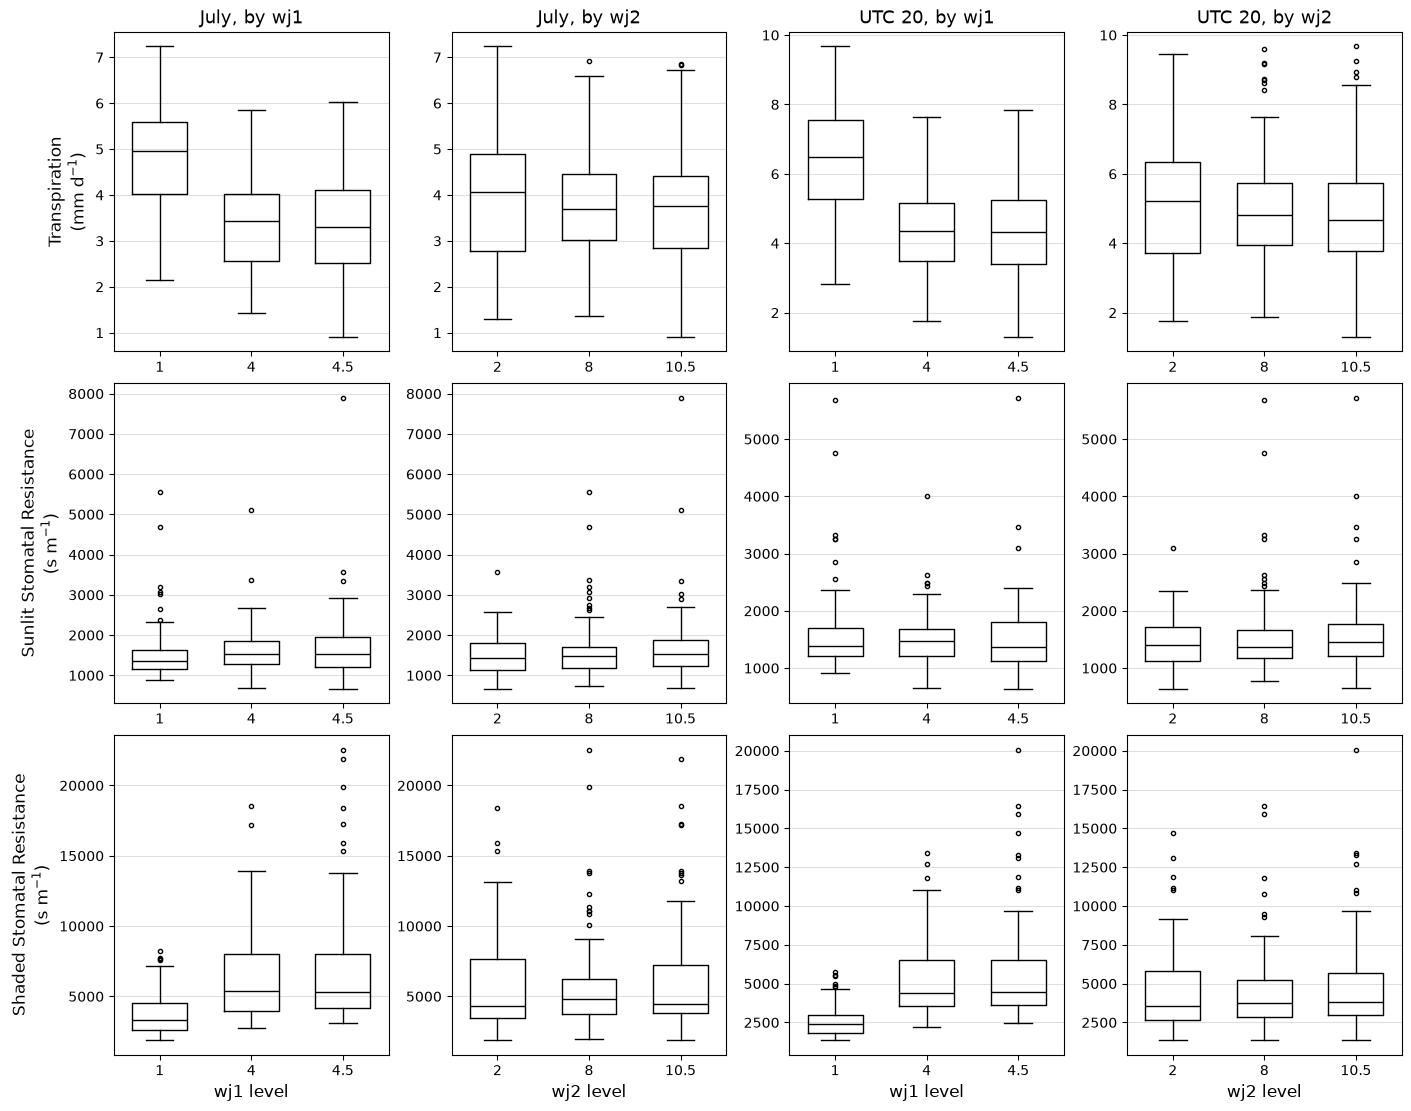

R^2 gain from treating wj1 and wj2 as categories: at most 0.008 over the 78 slices


In [15]:
box_slices = [('monthly', 'July', MONTHS.index('July')), ('hourly', 'UTC 20', HOURS.index('GMT_20'))]
levels = {n: np.unique(X[:, names.index(n)]) for n in ('wj1', 'wj2')}

lines = []
fig, axes = plt.subplots(3, 4, figsize=(14, 11), layout='constrained')
for r, q in enumerate(QOIS):
    for c, (scale, lab, i) in enumerate(box_slices):
        f = F[scale, q][:, i] * scale_factor[q]
        for k, n in enumerate(('wj1', 'wj2')):
            ax = axes[r, 2 * c + k]
            xn = X[:, names.index(n)]
            groups_f = [f[xn == v] for v in levels[n]]
            ax.boxplot(groups_f, tick_labels=[f'{v:g}' for v in levels[n]], widths=.6,
                       medianprops=dict(color='k'), flierprops=dict(ms=3))
            ax.grid(True, axis='y', alpha=.4)
            if r == 0:
                ax.set_title(f'{lab}, by {n}', fontsize=13)
            if r == 2:
                ax.set_xlabel(f'{n} level', fontsize=12)
            if 2 * c + k == 0:
                ax.set_ylabel(f'{qoi_title[q]}\n({qoi_unit[q]})', fontsize=12)
            lines.append(f'{q:>8} {lab:>6}: weight {W[scale, q][i, names.index(n)]:+.2f}, medians by {n} level '
                         f'{levels[n].tolist()}: ' + ', '.join(f'{np.median(g):.3g}' for g in groups_f))
print('\n'.join(lines))
plt.show()

A = np.hstack([np.ones((len(XX), 1)), XX])
D = np.hstack([A] + [(X[:, [names.index(n)]] == levels[n][1]).astype(float) for n in ('wj1', 'wj2')])
gain = []
for key, Fk in F.items():
    for i in range(Fk.shape[1]):
        f = Fk[:, i]
        tss = np.sum((f - f.mean())**2)
        r_lin = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
        r_cat = f - D @ np.linalg.lstsq(D, f, rcond=None)[0]
        gain.append((r_lin @ r_lin - r_cat @ r_cat) / tss)
print(f'R^2 gain from treating wj1 and wj2 as categories: at most {max(gain):.3f} over the 78 slices')

In both slices, transpiration and shaded resistance change mainly between wj1 = 1 and wj1 = 4, and levels 4 and 4.5 give similar outputs. The medians by wj1 level are 4.96, 3.43, 3.31 mm d<sup>−1</sup> (transpiration, July) and 6.48, 4.35, 4.33 (UTC 20); for shaded resistance they are 3.34e3, 5.41e3, 5.34e3 s m<sup>−1</sup> (July) and 2.39e3, 4.4e3, 4.46e3 (UTC 20). The normalized levels −1, 0.714, 1 have the same spacing, so a straight line in normalized wj1 follows this step, and the weight has the sign of the change from level 1 to the other two. Sunlit resistance, and every output against wj2, differ less between levels, in line with their small weights in these slices (printed beside the medians). Treating wj1 and wj2 as categories raises $R^2$ by at most 0.008 in any of the 78 slices, so the linear model loses little by treating them as numbers. Still, their weights measure the effect of switching among three hard-coded formulations, not of a continuous parameter.

### Conclusions

One direction describes transpiration well in every slice ($R^2$ at least 0.89) and shaded stomatal resistance reasonably (0.75 to 0.82). For sunlit resistance it is weaker in summer: $R^2$ is 0.46 in July and 0.37 to 0.44 in the hours UTC 20–23 of June–August, and the summary plots show wide scatter about the trend there, as [[1]](https://doi.org/10.1175/JHM-D-16-0053.1) notes for the hourly resistances (p. 909: "resistance values spread farther from the perceived univariate trend"). The weights are still informative where the trend is loose, but a one-dimensional model of sunlit resistance would miss much of its variation in those hours.

This analysis tells a modeller which parameters need careful specification for accurate predictions of these outputs; parameters with large weights affect the output more than the others, so comparatively large uncertainty in them leads to large uncertainty in the output. It also shows that the active subspace method can be used with hydrologic models; implementations of these models that compute gradients would let us estimate $\mathbf C$ itself, build better one-dimensional subspaces, or find higher-dimensional structure that the gradient-free algorithm cannot detect.

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 25.1 s
